# EUR/SEK: calibrate tail-weighted HJB volatility regimes with yfinance

The existing C++ solver uses an exogenous finite-state volatility **continuous-time Markov chain**. This notebook estimates regime volatilities and the generator **Q** from intraday FX closes, then exports the pair-specific result for automatic loading by Dash.

**Regime construction is configurable:**

- `REGIME_METHOD="tail_weighted"` (default): the final state always contains the **highest 5%** of rolling-volatility observations when `EXTREME_QUANTILE=0.95`, regardless of whether `N_REGIMES` is 3, 6, or another supported number. For **six states** the quantile bucket sizes are **30%, 20%, 20%, 15%, 10%, 5%**. Intermediate state thresholds adapt with N while the top tail cutoff stays at the same percentile.
- `REGIME_METHOD="equal_frequency"`: original equal-population buckets (each contains about 1/N of the data). This is retained for comparison.
- `EXTREME_QUANTILE` may be changed (for example 0.90 or 0.975). It is a **percentile**, not a fixed absolute volatility: if the historical sample changes, its value in pips/√minute can change.

**Solver contract:** `sigmaPips` is in quote-price units of 0.0001/√minute (EUR/SEK: pips/√minute), and `ratesPerMinute` has **zero diagonal**. The exported `generatorQPerMinute` has negative diagonal, with each row summing to zero. The dashboard infers the dimension from Q and loads sigma along with it.

**Method:** restrict 5-minute EUR/SEK closes to 07:45–17:15 in Europe/Copenhagen, estimate 60-minute trailing realized volatility without crossing session gaps, classify each window, use conditional RMS volatility within each state, and estimate Q from the likelihood of discrete observations, `P(Δ)=expm(ΔQ)`.

**Caution:** Yahoo intraday FX history is short and indicative. Rolling windows introduce mechanical persistence, and estimates in rare tail states have higher sampling uncertainty. Validate regime dwell times and stability before applying the calibration in production.


## 1. Dependencies and calibration settings

From the project root, run `python -m pip install -e ".[calibration]"` once. Open this notebook in VS Code or Jupyter. The first code cell locates the project from the current directory or an editable installation; you can also specify `PROJECT_ROOT` explicitly. A live connection to Yahoo Finance is required for the download.

Set **`N_REGIMES`** in the next cell to choose how many states the calibration produces (from 2 to 12, matching the C++ HJB solver). For example, `N_REGIMES = 5` produces five volatility levels and a 5×5 rate matrix. All figures, labels and exports adapt automatically. The saved file is automatically discovered by the dashboard on the next Solve; no editing `fx_pair_defaults.json` is needed.

**macOS permission troubleshooting:** If `Path.cwd()` raises `PermissionError: Operation not permitted`, VS Code's Jupyter kernel does not have access to its current directory. Set `PROJECT_ROOT` in the next cell to the **absolute path of the extracted project** (the folder containing `python/` and `notebooks/`) and rerun the cell. The notebook will switch the kernel's working directory there. You can alternatively set the `LADDER_PRICING_ROOT` environment variable. If macOS also blocks access to that explicit path, grant VS Code/Python folder access in **System Settings → Privacy & Security** or move the project to a permitted directory; restart the kernel after permission changes.


In [1]:
from pathlib import Path
import importlib.util
import json
import os
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# Optional: set this to your EXTRACTED project's absolute folder on macOS,
# e.g. PROJECT_ROOT = "/Users/yourname/Projects/Ladder_Pricing".
# Leave None for automatic discovery when Jupyter's working directory is accessible.
PROJECT_ROOT = None

def _find_project_root():
    candidates = []
    if PROJECT_ROOT:
        candidates.append(Path(PROJECT_ROOT).expanduser())
    env_root = os.environ.get("LADDER_PRICING_ROOT")
    if env_root:
        candidates.append(Path(env_root).expanduser())
    try:
        candidates.append(Path.cwd())
    except OSError as exc:
        print(f"Cannot read Jupyter working directory ({exc}); trying other locations.")

    # If the project package was installed in editable mode, it provides another
    # reliable path without calling os.getcwd() (which macOS may block).
    try:
        spec = importlib.util.find_spec("trinity")
        if spec and spec.origin:
            candidates.append(Path(spec.origin).parent.parent.parent)
    except (ImportError, OSError, ValueError):
        pass

    for candidate in candidates:
        # Running either in the project root or its notebooks/ subfolder works.
        for root in (candidate, candidate.parent):
            try:
                if (root / "python" / "trinity" / "volatility_calibration.py").is_file():
                    return root.resolve()
            except OSError:
                continue
    raise RuntimeError(
        "Cannot locate the extracted Ladder Pricing project. Set PROJECT_ROOT "
        "above to its absolute path (the folder containing python/trinity and "
        "notebooks). On macOS, grant VS Code / Python access to that folder "
        "or move the project to an accessible folder if permission is denied."
    )

ROOT = _find_project_root()
try:
    os.chdir(ROOT)  # Repair an inaccessible inherited kernel working directory.
except OSError as exc:
    raise RuntimeError(
        f"Cannot enter project directory {ROOT}: {exc}. "
        "Allow VS Code / Python to access this folder in macOS privacy settings."
    ) from exc
sys.path.insert(0, str(ROOT / "python"))

from trinity.volatility_calibration import (
    SOLVER_PIP_SIZE, yahoo_fx_closes, calibrate_from_closes,
    label_volatility_regimes, regime_quantile_boundaries, save_calibration_artifact,
)

PAIR = "EURSEK"        # EURSEK -> Yahoo EURSEK=X
LOOKBACK_DAYS = 55    # <=58 days because Yahoo limits intraday history
BAR_MINUTES = 5
VOL_WINDOW_MINUTES = 60
N_REGIMES = 6          # choose 2–12; the highest tail is unchanged when changing N
REGIME_METHOD = "tail_weighted"  # "tail_weighted" or "equal_frequency"
EXTREME_QUANTILE = 0.95  # top 5% is the highest volatility state (tail-weighted mode)
CTMC_TOPOLOGY = "auto"  # 2–3 states: full Q; 4–12 states: adjacent-only Q (or "full")
SAVE_FOR_DASHBOARD = True  # atomic per-pair Q + sigma export, discovered on the next Solve

if type(N_REGIMES) is not int or not 2 <= N_REGIMES <= 12:
    raise ValueError("N_REGIMES must be an integer between 2 and 12")

if REGIME_METHOD not in ("tail_weighted", "equal_frequency"):
    raise ValueError("REGIME_METHOD must be 'tail_weighted' or 'equal_frequency'")

print("Number of volatility states:", N_REGIMES)
print("Regime allocation:", REGIME_METHOD)
if REGIME_METHOD == "tail_weighted":
    print(f"Highest state contains the top {(1-EXTREME_QUANTILE):.1%} of observations")
print("Target pair:", PAIR)
print("Project root:", ROOT)
if PAIR.endswith("JPY"):
    print("WARNING: the native engine uses 0.0001 quote-price units, NOT conventional 0.01 JPY pips.")

Number of volatility states: 6
Regime allocation: tail_weighted
Highest state contains the top 5.0% of observations
Target pair: EURSEK
Project root: /Users/jshellen/Repos/finance/hjb_ladder


## 2. Download indicative FX intraday bars

Yahoo uses a ticker such as `EURSEK=X`. Missing or timezone-naive data raises an error rather than silently fabricating prices or interpreting the time zone incorrectly.

In [2]:
closes = yahoo_fx_closes(PAIR, lookback_days=LOOKBACK_DAYS, interval_minutes=BAR_MINUTES)
print(f"{PAIR}: {len(closes):,} bars")
print("Time range (Copenhagen):", closes.index.min(), "to", closes.index.max())
display(closes.to_frame().tail(8))

EURSEK: 11,168 bars
Time range (Copenhagen): 2026-08-21 01:00:00+02:00 to 2026-10-15 08:10:00+02:00


,close
Datetime,
2026-10-15 07:35:00+02:00,11.18166
2026-10-15 07:40:00+02:00,11.18203
2026-10-15 07:45:00+02:00,11.18054
2026-10-15 07:50:00+02:00,11.18022
2026-10-15 07:55:00+02:00,11.17911
2026-10-15 08:00:00+02:00,11.18101
2026-10-15 08:05:00+02:00,11.18052
2026-10-15 08:10:00+02:00,11.18160


## 3. Estimate realized volatility

For a 5-minute close-to-close price change ΔS measured in pips, calculate within each session:

\[
\widehat{\sigma}_t=\sqrt{\frac{1}{W}\sum_{k\,\in\,\text{last }W/\Delta\text{ bars}}\left(\frac{S_k-S_{k-1}}{10^{-4}}\right)^2}\,,\quad W=60\text{ minutes}.
\]

This estimates spot-price volatility in **pips/√minute**. It does not annualize volatility. Only **complete** rolling windows of consecutive bars are used; missing bars, overnight/weekends and local-session boundaries reset the estimator. The fixed 07:45–17:15 session is interpreted in Copenhagen's local time including DST.


In [3]:
result = calibrate_from_closes(
    closes, regimes=N_REGIMES, interval_minutes=BAR_MINUTES,
    window_minutes=VOL_WINDOW_MINUTES, pip_size=SOLVER_PIP_SIZE,
    transition_topology=CTMC_TOPOLOGY,
    regime_method=REGIME_METHOD, extreme_quantile=EXTREME_QUANTILE,
)
names = (["Low", "High"] if N_REGIMES == 2 else
         ["Low", "Normal", "High"] if N_REGIMES == 3 else
         [f"Regime {i+1}" for i in range(N_REGIMES)])
print("CTMC transition topology:",
      ("adjacent" if N_REGIMES > 3 else "full") if CTMC_TOPOLOGY == "auto" else CTMC_TOPOLOGY)
valid = result.regime_frame
print(f"Full-session candles: {len(result.vol_frame):,}")
print(f"Valid rolling volatility observations: {len(valid):,}")
print(f"Distinct Copenhagen sessions: {valid['sessionDate'].nunique()}")
print("State cut points (pips/√minute):", np.round(result.thresholds, 3))
q_bounds = regime_quantile_boundaries(N_REGIMES, method=REGIME_METHOD,
                                     extreme_quantile=EXTREME_QUANTILE)
print("State percentile boundaries:", np.round(q_bounds * 100, 2))
print("Empirical state weights (%):", np.round(
    100 * valid['regime'].value_counts(normalize=True).reindex(range(N_REGIMES), fill_value=0).to_numpy(), 2))
display(valid.tail(8))

CTMC transition topology: adjacent
Full-session candles: 4,452
Valid rolling volatility observations: 3,978
Distinct Copenhagen sessions: 39
State cut points (pips/√minute): [ 9.063 10.675 13.095 15.664 19.888]
State percentile boundaries: [30. 50. 70. 85. 95.]
Empirical state weights (%): [30.02 19.98 19.98 15.01 10.01  5.  ]


,close,returnPips,sigmaPips,sessionDate,regime
timeCopenhagen,,,,,
2026-10-14 16:35:00+02:00,11.19428,36.497116,19.303856,2026-10-14,4
2026-10-14 16:40:00+02:00,11.19194,-23.393631,19.530432,2026-10-14,4
2026-10-14 16:45:00+02:00,11.19509,31.499863,19.460477,2026-10-14,4
2026-10-14 16:50:00+02:00,11.19789,27.999878,19.675599,2026-10-14,4
2026-10-14 16:55:00+02:00,11.19678,-11.100769,11.688527,2026-10-14,2
2026-10-14 17:00:00+02:00,11.20379,70.095062,14.778837,2026-10-14,3
2026-10-14 17:05:00+02:00,11.21027,64.802170,15.665389,2026-10-14,4
2026-10-14 17:10:00+02:00,11.20982,-4.501343,15.303983,2026-10-14,3


## Compare uniform and tail-weighted regime definitions

These tables compare state **volatility levels and sample occupancy**, not CTMC estimates. The Q matrix is fitted only for the method selected above. The six-state tail-weighted reference allocation uses 30/20/20/15/10/5%; for three states the top state is still the highest 5% of the *same* sample. The highest-state σ is therefore unchanged between three and six tail-weighted states on identical data (apart from numerical rounding).


,Method,N,Regime,Weight (%),σ (pips/√min),Upper percentile (%)
0,equal_frequency,3,1,33.33,7.648,33.33
1,equal_frequency,3,2,33.33,10.810,66.67
2,equal_frequency,3,3,33.33,16.949,100.00
3,equal_frequency,6,1,16.67,6.526,16.67
4,equal_frequency,6,2,16.67,8.626,33.33
5,equal_frequency,6,3,16.67,10.013,50.00
6,equal_frequency,6,4,16.67,11.552,66.67
7,equal_frequency,6,5,16.67,13.855,83.33
8,equal_frequency,6,6,16.67,19.560,100.00
9,tail_weighted,3,1,60.01,9.007,60.00


Highest volatility state for 3 vs 6 states:


,Method,N,σ (pips/√min),Weight (%)
2,equal_frequency,3,16.949,33.33
8,equal_frequency,6,19.560,16.67
11,tail_weighted,3,24.290,5.00
17,tail_weighted,6,24.290,5.00


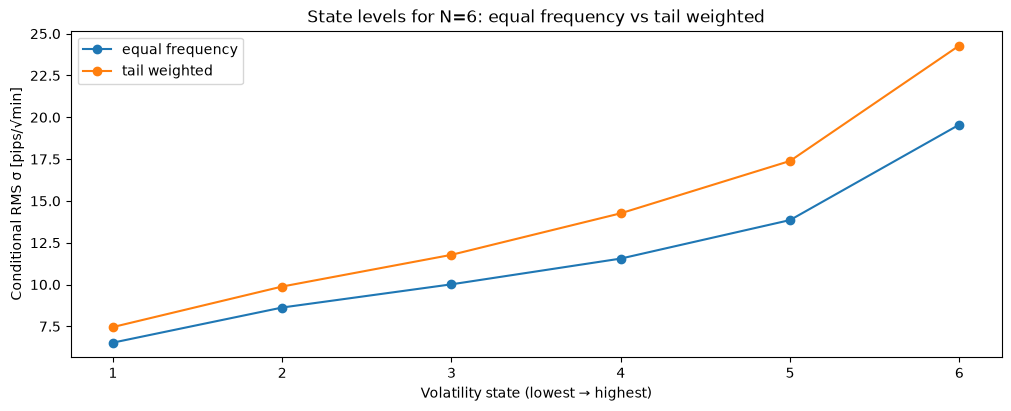

In [4]:
regime_comparison = []
for method in ("equal_frequency", "tail_weighted"):
    for n in (3, 6):
        selected, levels, thresholds = label_volatility_regimes(
            result.vol_frame, regimes=n, method=method,
            extreme_quantile=EXTREME_QUANTILE,
        )
        fractions = selected["regime"].value_counts(normalize=True).reindex(range(n), fill_value=0)
        quantile_edges = regime_quantile_boundaries(n, method=method, extreme_quantile=EXTREME_QUANTILE)
        for i in range(n):
            regime_comparison.append({
                "Method": method, "N": n, "Regime": i+1,
                "Weight (%)": round(100 * fractions[i], 2),
                "σ (pips/√min)": round(levels[i], 3),
                "Upper percentile (%)": round(100 * quantile_edges[i], 2) if i < n-1 else 100.0,
            })
comparison_table = pd.DataFrame(regime_comparison)
display(comparison_table)
comparison_high = comparison_table.loc[
    comparison_table["Regime"] == comparison_table["N"],
    ["Method", "N", "σ (pips/√min)", "Weight (%)"]
]
print("Highest volatility state for 3 vs 6 states:")
display(comparison_high)

fig, ax = plt.subplots(figsize=(10, 4), constrained_layout=True)
for k, (method, n) in enumerate((("equal_frequency", N_REGIMES), ("tail_weighted", N_REGIMES))):
    subset = comparison_table[(comparison_table["Method"] == method) & (comparison_table["N"] == n)]
    # The plot uses the chosen N; if it differs from 3 or 6, compute on demand.
    if len(subset) != N_REGIMES:
        _, levels, _ = label_volatility_regimes(result.vol_frame, regimes=N_REGIMES,
                                               method=method, extreme_quantile=EXTREME_QUANTILE)
    else:
        levels = subset["σ (pips/√min)"].to_numpy()
    ax.plot(np.arange(1, N_REGIMES+1), levels, marker="o", label=method.replace('_', ' '))
ax.set_xlabel("Volatility state (lowest → highest)")
ax.set_ylabel("Conditional RMS σ [pips/√min]")
ax.set_xticks(range(1, N_REGIMES+1))
ax.set_title(f"State levels for N={N_REGIMES}: equal frequency vs tail weighted")
ax.legend()
plt.show()


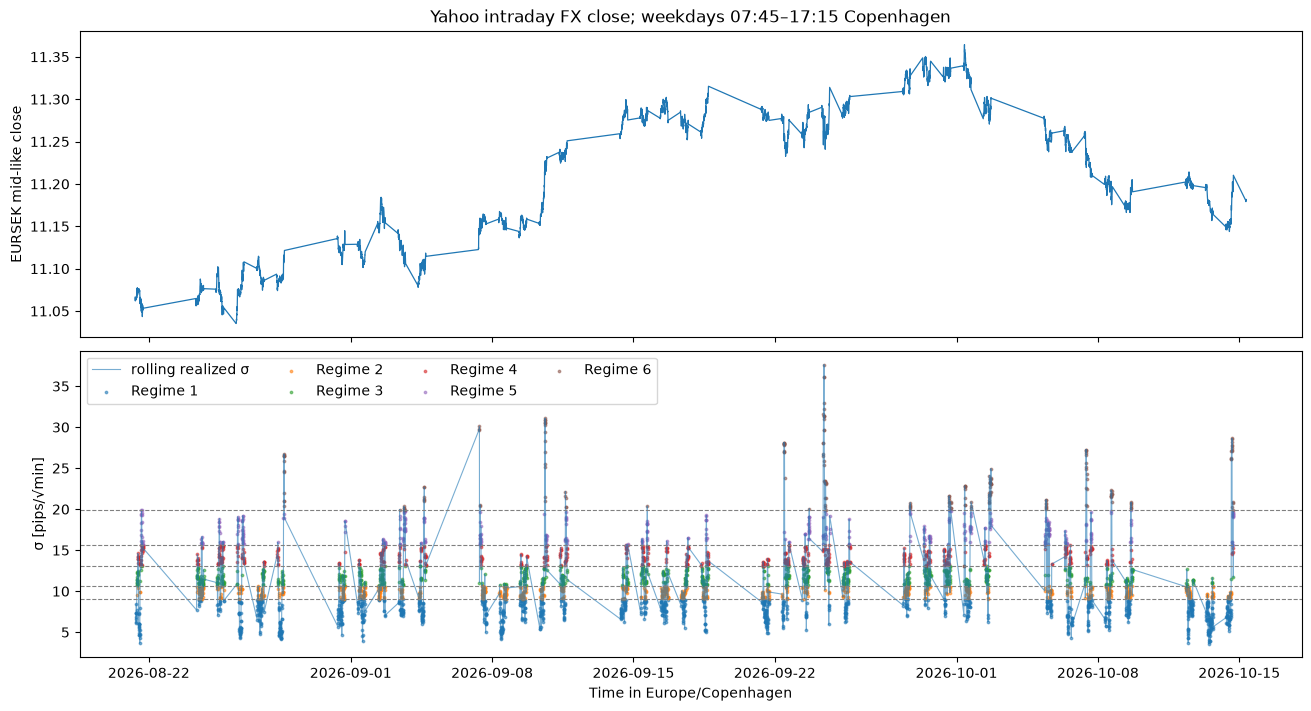

In [5]:
fig, axes = plt.subplots(2, 1, figsize=(13, 7), sharex=True, constrained_layout=True)
axes[0].plot(result.vol_frame.index, result.vol_frame['close'], linewidth=0.9)
axes[0].set_ylabel(f"{PAIR} mid-like close")
axes[0].set_title("Yahoo intraday FX close; weekdays 07:45–17:15 Copenhagen")
axes[1].plot(valid.index, valid['sigmaPips'], linewidth=0.8, alpha=0.6, label="rolling realized σ")
for state, label in enumerate(names):
    subset = valid.loc[valid['regime'] == state]
    axes[1].scatter(subset.index, subset['sigmaPips'], s=3, label=label, alpha=0.55)
for line in result.thresholds:
    axes[1].axhline(line, linestyle="--", color="gray", linewidth=0.8)
axes[1].set_ylabel("σ [pips/√min]")
axes[1].set_xlabel("Time in Europe/Copenhagen")
axes[1].legend(ncol=4, loc="upper left")
plt.show()

## 4. Fit the Markov generator

For adjacent observed volatility states sampled Δ = 5 minutes apart, compute the count matrix \(N_{ij}\), including *stays* on the diagonal. Estimate a genuine continuous-time generator \(Q\) by maximizing

\[
\ell(Q)=\sum_{i,j}N_{ij}\log\left([e^{\Delta Q}]_{ij}\right),\qquad
Q_{ij}\ge 0\ (i\ne j),\quad Q_{ii}=-\sum_{j\ne i}Q_{ij}.
\]

This is preferable to using `N_ij / (time in state i)` when observations are discrete: several unobserved regime switches can occur between two bars. Positivity is enforced in optimization; the solver's input matrix has a **zero diagonal**, with the negative diagonal shown here only for diagnostic purposes.


**Transition structure:** `CTMC_TOPOLOGY="auto"` preserves the original full-rate calibration for 2–3 states and fits *adjacent-state* transitions for 4–12 states. This reduces the number of free parameters from N(N−1) to 2(N−1). The fitted `expm(ΔQ)` can still show jumps over multiple states between observed bars. Use `"full"` only if you have enough history and want unrestricted direct transitions; estimating many free rates from short Yahoo history is prone to overfitting.


In [6]:
q = result.generator
rates = np.asarray(result.model['ratesPerMinute'])
counts = pd.DataFrame(result.transition_counts, index=names, columns=names)
q_table = pd.DataFrame(q, index=names, columns=names)

summary = pd.DataFrame({
    "sigma (pips/√min)": result.model['sigmaPips'],
    "observed windows": [int((valid['regime'] == i).sum()) for i in range(N_REGIMES)],
    "observed exits": [int(result.transition_counts[i].sum() - result.transition_counts[i, i]) for i in range(N_REGIMES)],
    "exit intensity (1/min)": -np.diag(q),
    "expected dwell (min)": 1.0 / (-np.diag(q)),
}, index=names)
print("Volatility levels and implied regime durations:")
display(summary.round(4))
print("Observed transitions; within-day adjacent bars only (stays included):")
display(counts)
print("Full continuous-time generator Q [1/min], rows sum to zero:")
display(q_table.round(6))
print("Solver input ratesPerMinute [1/min], zero diagonal:")
display(pd.DataFrame(rates, index=names, columns=names).round(6))

A = q.T.copy()
A[-1] = 1
b = np.zeros(N_REGIMES)
b[-1] = 1
stationary = np.linalg.solve(A, b)
print("Stationary regime probabilities:", dict(zip(names, np.round(stationary, 3))))

Volatility levels and implied regime durations:


,sigma (pips/√min),observed windows,observed exits,exit intensity (1/min),expected dwell (min)
Regime 1,7.4580,1194,152,0.0304,32.8656
Regime 2,9.8809,795,255,0.0890,11.2417
Regime 3,11.7771,795,224,0.0768,13.0176
Regime 4,14.2595,597,156,0.0729,13.7210
Regime 5,17.3889,398,91,0.0607,16.4771
Regime 6,24.2900,199,30,0.0345,29.0271


Observed transitions; within-day adjacent bars only (stays included):


,Regime 1,Regime 2,Regime 3,Regime 4,Regime 5,Regime 6
Regime 1,1034,130,18,1,3,0
Regime 2,125,538,122,6,2,0
Regime 3,14,107,563,91,11,1
Regime 4,2,10,82,429,59,3
Regime 5,0,2,3,60,299,26
Regime 6,0,0,2,4,24,168


Full continuous-time generator Q [1/min], rows sum to zero:


,Regime 1,Regime 2,Regime 3,Regime 4,Regime 5,Regime 6
Regime 1,-0.030427,0.030427,0.000000,0.000000,0.000000,0.000000
Regime 2,0.042492,-0.088955,0.046463,0.000000,0.000000,0.000000
Regime 3,0.000000,0.042402,-0.076819,0.034417,0.000000,0.000000
Regime 4,0.000000,0.000000,0.041204,-0.072881,0.031677,0.000000
Regime 5,0.000000,0.000000,0.000000,0.043433,-0.060690,0.017257
Regime 6,0.000000,0.000000,0.000000,0.000000,0.034451,-0.034451


Solver input ratesPerMinute [1/min], zero diagonal:


,Regime 1,Regime 2,Regime 3,Regime 4,Regime 5,Regime 6
Regime 1,0.000000,0.030427,0.000000,0.000000,0.000000,0.000000
Regime 2,0.042492,0.000000,0.046463,0.000000,0.000000,0.000000
Regime 3,0.000000,0.042402,0.000000,0.034417,0.000000,0.000000
Regime 4,0.000000,0.000000,0.041204,0.000000,0.031677,0.000000
Regime 5,0.000000,0.000000,0.000000,0.043433,0.000000,0.017257
Regime 6,0.000000,0.000000,0.000000,0.000000,0.034451,0.000000


Stationary regime probabilities: {'Regime 1': np.float64(0.258), 'Regime 2': np.float64(0.185), 'Regime 3': np.float64(0.203), 'Regime 4': np.float64(0.169), 'Regime 5': np.float64(0.123), 'Regime 6': np.float64(0.062)}


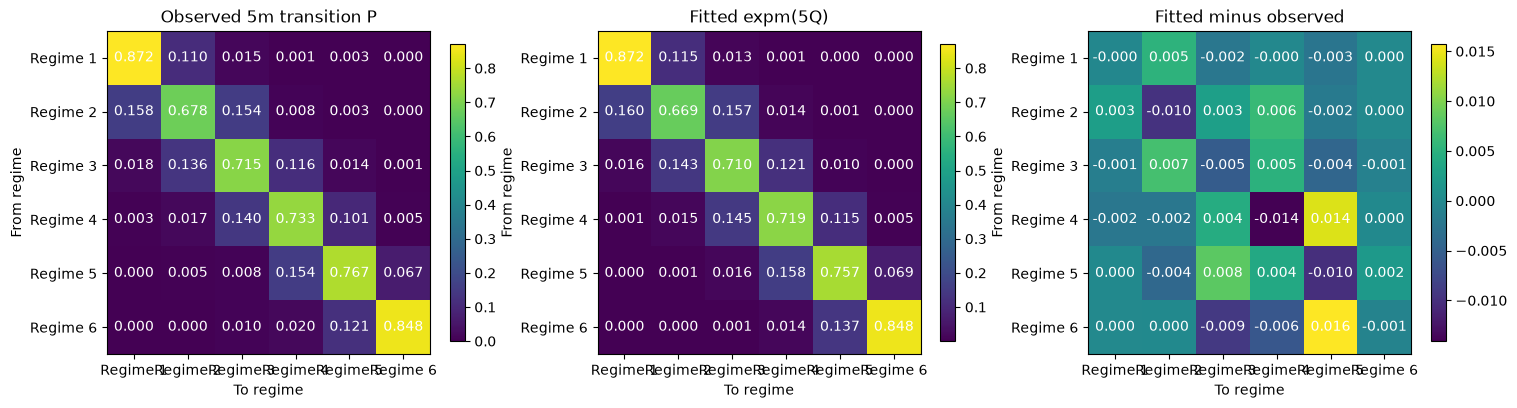

Largest absolute transition-probability fit error: 0.0158


In [7]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4), constrained_layout=True)
for ax, matrix, title in zip(
    axes,
    [result.observed_transition_probabilities, result.fitted_transition_probabilities,
     result.fitted_transition_probabilities - result.observed_transition_probabilities],
    ["Observed 5m transition P", "Fitted expm(5Q)", "Fitted minus observed"],
):
    image = ax.imshow(matrix, cmap="viridis", aspect="equal")
    ax.set_xticks(range(N_REGIMES), names)
    ax.set_yticks(range(N_REGIMES), names)
    ax.set_xlabel("To regime")
    ax.set_ylabel("From regime")
    ax.set_title(title)
    for i in range(N_REGIMES):
        for j in range(N_REGIMES):
            ax.text(j, i, f"{matrix[i, j]:.3f}", ha="center", va="center", color="white")
    fig.colorbar(image, ax=ax, fraction=0.046, pad=0.04)
plt.show()

errors = result.fitted_transition_probabilities - result.observed_transition_probabilities
print(f"Largest absolute transition-probability fit error: {np.max(np.abs(errors)):.3g}")
if min(summary['observed exits']) < 20:
    print("WARNING: fewer than 20 observed exits from at least one state; Q may be unstable.")
if min(-np.diag(q)) < 1e-5:
    print("WARNING: one state has an extremely small exit rate.")
if np.max(rates) >= 2.0 / BAR_MINUTES * 0.99:
    print("WARNING: rate reaches optimization bound; use higher frequency data.")

## 5. Save calibrated Q for the dashboard

The notebook writes `notebooks/output/{PAIR}_volatility_regimes.json` by default. It contains the **full generator Q** with negative diagonal, the corresponding state sigma levels, regime thresholds, and calibration metadata. The dashboard **automatically discovers and validates** this pair-specific file whenever it builds a fresh HJB config. The Q dimension sets the number of states; sigma is not inferred from Q alone. No manual edit to `fx_pair_defaults.json`, dashboard restart, or native recompilation is required. The packaged defaults remain a fallback if no calibration file exists.

If a calibration file exists but is malformed or has mismatched dimensions, the dashboard returns a validation error rather than silently reverting to defaults.


In [8]:
model = result.model
assert len(model['sigmaPips']) == N_REGIMES
assert len(model['ratesPerMinute']) == N_REGIMES
assert all(abs(row[i]) < 1e-14 for i, row in enumerate(model['ratesPerMinute']))
assert np.allclose(q.sum(axis=1), 0, atol=1e-12)
assert all(a < b for a, b in zip(model['sigmaPips'], model['sigmaPips'][1:]))
print(f"State count inferred from Q: {q.shape[0]}")
print("Q [1/min] (negative diagonal):")
print(json.dumps(q.tolist(), indent=2))
print("σ [pips/√min]:", model['sigmaPips'])

if SAVE_FOR_DASHBOARD:
    destination = save_calibration_artifact(PAIR, result)
    print("Saved Q + sigma calibration:", destination)
    print("Dashboard will use this model on the next Solve (no restart required).")
else:
    print("Not saved; dashboard parameters unchanged (SAVE_FOR_DASHBOARD=False).")


State count inferred from Q: 6
Q [1/min] (negative diagonal):
[
  [
    -0.030426980234345494,
    0.030426980234345494,
    0.0,
    0.0,
    0.0,
    0.0
  ],
  [
    0.0424922093604727,
    -0.0889547452561555,
    0.0464625358956828,
    0.0,
    0.0,
    0.0
  ],
  [
    0.0,
    0.04240206041511949,
    -0.07681928198181698,
    0.03441722156669749,
    0.0,
    0.0
  ],
  [
    0.0,
    0.0,
    0.04120430155856493,
    -0.07288085732969227,
    0.03167655577112734,
    0.0
  ],
  [
    0.0,
    0.0,
    0.0,
    0.04343341230566833,
    -0.0606904007051349,
    0.01725698839946657
  ],
  [
    0.0,
    0.0,
    0.0,
    0.0,
    0.034450550882002044,
    -0.034450550882002044
  ]
]
σ [pips/√min]: [7.458002613737594, 9.880891515996396, 11.77707929032085, 14.259500469590103, 17.388885421154022, 24.29000298459863]
Saved Q + sigma calibration: /Users/jshellen/Repos/finance/hjb_ladder/notebooks/output/EURSEK_volatility_regimes.json
Dashboard will use this model on the next Solve (no

## 6. Interpretation and checks before deployment

- **Volatility scale:** `sigmaPips` is in 0.0001 quote-price units per √minute because the current solver uses `sigmaPips / 10000`. For JPY crosses this is **not** the conventional market pip size; the app's unit convention would need review before deploying JPY calibrations.
- **Frequency dependence:** Volatility windows overlap; changing `VOL_WINDOW_MINUTES` changes state persistence and the estimated rate matrix. A 60-minute rolling estimate is not an instantly observed spot-variance state.
- **Calibration sample:** 5-minute indicative bars and approximately 55 calendar days provide a *prototype*, not several years of market regimes. Check stability by refitting on different subperiods and using the desk's recorded price history.
- **HJB usage:** `Q` is exogenous and independent of inventory. The calibrated matrix goes into the existing stationary joint `(q, σ)` HJB and the Monte Carlo's volatility switching. No other flow, markout or risk parameters are modified.
- **No future information in live state:** If you later build a live volatility observer, calculate its trailing realized volatility using only past bars and use **the same** window and cut points. This notebook estimates parameters offline only; it does not feed live volatility state observations into the pricing engine.

- **Tail threshold stability:** With `REGIME_METHOD="tail_weighted"`, the final state always represents observations at or above the chosen percentile **within the same dataset**. Its absolute cut point moves if the underlying distribution changes; it is not a structural high-volatility threshold.
- **Rare-state robustness:** The highest state has only 5% of valid windows at the default cutoff; small observed exit counts and short sample periods imply substantial uncertainty in the estimated Q row.
- **State count:** More states increase the number of HJB states and the numerical cost. With only Yahoo intraday history, high regime counts may give unreliable exit rates. Check the observed transitions and model-vs-empirical matrix before applying the result.
